# SalesInsight PY — Notebook de estudo e apresentação

Este notebook roda o projeto **célula por célula**, no Colab, com uma explicação
de professor para aluno antes de cada bloco de código: o que a célula faz, por
que foi escrita assim, e o comando exato que você está executando.

Use isto como **roteiro do vídeo**: rode cada célula, leia a explicação em voz
alta (ou reescreva com suas palavras) e mostre o resultado no console/gráfico
antes de passar para a próxima.

Mini-Projeto Avaliativo M1.1 — Desenvolvedor(a) em IA para Análise Preditiva, Módulo 01.


## Passo 0 — Instalação das bibliotecas

**O que é:** o Python sozinho não sabe manipular tabelas de dados nem desenhar
gráficos — isso vem de bibliotecas externas. `pandas` é a biblioteca de
tabelas (DataFrames); `numpy` é cálculo numérico vetorizado; `matplotlib` e
`seaborn` desenham os gráficos.

**No Google Colab:** `pandas`, `numpy` e `matplotlib` já vêm pré-instalados.
Só `seaborn` as vezes precisa ser garantido. O comando abaixo usa `!pip install`
— o `!` no início de uma célula do Colab/Jupyter diz "execute isto no terminal
do sistema, não como código Python".

**Comando que eu uso e vou falar no vídeo:** `!pip install pandas numpy matplotlib seaborn`


In [1]:
!pip install -q pandas numpy matplotlib seaborn
print("Bibliotecas prontas.")


Bibliotecas prontas.


## Passo 1 — Importar as bibliotecas (setup)

**O que é:** `import` traz uma biblioteca para dentro do programa, com um
apelido (`as`) para não precisar digitar o nome completo toda hora
(`pd.DataFrame` em vez de `pandas.DataFrame`).

**Linha por linha:**
- `import json`, `import os`, `import random`: módulos **nativos** do Python
  (já vêm instalados, não precisam de `pip install`). `json` lê/escreve
  arquivos JSON; `os` cria pastas e monta caminhos de arquivo; `random` gera
  números/escolhas aleatórias.
- `from datetime import datetime, timedelta`: traz só as duas classes de data
  que preciso, em vez do módulo `datetime` inteiro.
- `import matplotlib; matplotlib.use("Agg")`: define o "motor" de desenho do
  Matplotlib como um que só grava arquivo PNG, sem abrir janela — necessário
  porque o Colab não tem uma tela gráfica tradicional.
- `import matplotlib.pyplot as plt`: a API de plotagem do Matplotlib.
- `import numpy as np`: cálculo numérico vetorizado.
- `import pandas as pd`: DataFrames e leitura/escrita de CSV.
- `import seaborn as sns`: gráficos estatísticos construídos sobre o Matplotlib.


In [2]:
import json
import os
import random
from datetime import datetime, timedelta

import matplotlib
matplotlib.use("Agg")  # backend sem janela: so grava arquivos PNG
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PASTA_SAIDA = "outputs"
PASTA_GRAFICOS = os.path.join(PASTA_SAIDA, "graficos")
MESES_PT = {1: "Janeiro", 2: "Fevereiro", 3: "Marco", 4: "Abril",
            5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
            9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"}

print("Setup concluido.")


Setup concluido.


## RF01 — Gerar o dataset de vendas

**O que é:** em vez de usar um arquivo de dados pronto, eu **crio** o dataset
por código — uma lista de dicionários (`dados = []`), onde cada dicionário é
uma venda. No final, `pd.DataFrame(dados)` transforma essa lista em uma
tabela: cada chave do dicionário se torna uma coluna.

**Por que gerar por código:** o enunciado permitia gerar meu próprio dado, e
isso me dá controle total do experimento — decido quantos registros existem,
quais produtos, e consigo sujar propositalmente ~3% das datas
(`if random.random() < 0.03`) para ter algo real para limpar depois.

**Reprodutibilidade:** `random.seed(42)` e `np.random.seed(42)` fixam a
sequência de números "aleatórios" do computador. Com a mesma seed, qualquer
pessoa gera exatamente os mesmos 200 registros, em qualquer máquina — isso é
o que torna o experimento reproduzível.

**Comando que eu falo no vídeo:** "Gero 200 vendas com `for i in range(200)`,
escolhendo produto, quantidade e preço aleatoriamente, mas com seed fixa."


In [3]:
def gerar_dataset_vendas(n_registros=200, seed=42):
    """Gera um dataset sintetico de vendas com datas invalidas propositais.

    A seed fixa garante que qualquer pessoa gere exatamente os mesmos dados
    (reprodutibilidade).
    """
    random.seed(seed)
    np.random.seed(seed)

    produtos = ["Notebook", "Smartphone", "Tablet", "Monitor",
                "Teclado", "Mouse", "Headset"]
    categorias = {"Notebook": "Computadores", "Smartphone": "Celulares",
                  "Tablet": "Celulares", "Monitor": "Computadores",
                  "Teclado": "Perifericos", "Mouse": "Perifericos",
                  "Headset": "Perifericos"}
    precos = {"Notebook": 3500, "Smartphone": 2200, "Tablet": 1800,
              "Monitor": 1200, "Teclado": 250, "Mouse": 120,
              "Headset": 350}
    regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]

    data_inicio = datetime(2025, 1, 1)
    dados = []

    for i in range(n_registros):
        produto = random.choice(produtos)
        categoria = categorias[produto]
        quantidade = random.randint(1, 10)
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)
        data = data_inicio + timedelta(days=random.randint(0, 364))
        data_txt = data.strftime("%Y-%m-%d")
        cliente = f"Cliente_{random.randint(1, 50):03d}"

        if random.random() < 0.03:
            data_txt = "DATA INVALIDA"

        dados.append({
            "id_venda": i + 1,
            "data_venda": data_txt,
            "cliente": cliente,
            "produto": produto,
            "categoria": categoria,
            "regiao": random.choice(regioes),
            "quantidade": quantidade,
            "preco_unitario": preco,
        })

    return pd.DataFrame(dados)

df_bruto = gerar_dataset_vendas()
df_bruto.to_csv("vendas.csv", index=False)
print(f"Dataset gerado: {df_bruto.shape[0]} linhas, {df_bruto.shape[1]} colunas.")
df_bruto.head()


Dataset gerado: 200 linhas, 8 colunas.


,id_venda,data_venda,cliente,produto,categoria,regiao,quantidade,preco_unitario
0,1,2025-05-21,Cliente_016,Mouse,Perifericos,Sudeste,2,102.90
1,2,DATA INVALIDA,Cliente_003,Mouse,Perifericos,Sul,9,105.13
2,3,2025-10-15,Cliente_013,Smartphone,Celulares,Norte,9,2267.33
3,4,2025-05-23,Cliente_001,Monitor,Computadores,Sul,4,1181.72
4,5,2025-03-21,Cliente_014,Mouse,Perifericos,Nordeste,7,114.25


## RF02 — Inspecionar os dados

**O que é:** antes de limpar ou calcular qualquer coisa, eu olho a
**estrutura** dos dados — sem interpretar estatística ainda.

**Comando por comando:**
- `df.shape` → tupla `(linhas, colunas)`.
- `df.columns` → lista com o nome de cada coluna.
- `df.dtypes` → o tipo de cada coluna (`int64`, `float64`, `object`=texto).
- `df.isnull().sum()` → quantas células **vazias** existem, por coluna.
- `df.head()` → as 5 primeiras linhas.

**Pegadinha para explicar no vídeo:** `isnull()` só vê células realmente
vazias. A string `"DATA INVALIDA"` é texto preenchido, não vazio — por isso
`isnull()` dá 0 na coluna `data_venda`, mesmo com datas inválidas lá dentro.
Isso só vai aparecer depois, no RF03, quando eu tentar converter para data de
verdade.


In [4]:
def inspecionar_dados(df):
    """Exibe as informacoes estruturais do DataFrame (sem estatisticas)."""
    print("\n=== INSPECAO INICIAL DO DATASET ===")
    print(f"Shape: {df.shape}")
    print(f"\nColunas: {list(df.columns)}")
    print(f"\nTipos de dados:\n{df.dtypes}")
    print(f"\nValores nulos por coluna:\n{df.isnull().sum()}")
    print(f"\nPrimeiros registros:\n{df.head()}")
    return df

inspecionar_dados(df_bruto)



=== INSPECAO INICIAL DO DATASET ===
Shape: (200, 8)

Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda            str
cliente               str
produto               str
categoria             str
regiao                str
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3         4     2025-05-23  Cliente_001     Monitor  Com

,id_venda,data_venda,cliente,produto,categoria,regiao,quantidade,preco_unitario
0,1,2025-05-21,Cliente_016,Mouse,Perifericos,Sudeste,2,102.90
1,2,DATA INVALIDA,Cliente_003,Mouse,Perifericos,Sul,9,105.13
2,3,2025-10-15,Cliente_013,Smartphone,Celulares,Norte,9,2267.33
3,4,2025-05-23,Cliente_001,Monitor,Computadores,Sul,4,1181.72
4,5,2025-03-21,Cliente_014,Mouse,Perifericos,Nordeste,7,114.25
...,...,...,...,...,...,...,...,...
195,196,2025-04-21,Cliente_028,Headset,Perifericos,Sul,9,373.19
196,197,2025-07-24,Cliente_027,Monitor,Computadores,Nordeste,6,1317.87
197,198,2025-07-11,Cliente_010,Monitor,Computadores,Centro-Oeste,6,1259.44
198,199,2025-02-17,Cliente_028,Notebook,Computadores,Nordeste,2,3848.36


## RF03 — Limpar os dados (datas inválidas)

**O que é:** a etapa que remove a sujeira proposital do RF01, antes de
qualquer coluna derivada, agregação ou gráfico.

**Comando por comando:**
- `df = df.copy()` → cria uma cópia independente; evita alterar o DataFrame
  original (`df_bruto`), que ainda quero guardar intacto.
- `df[coluna].astype(str).str.strip()` → remove espaços sobrando no início/fim
  do texto.
- `pd.to_datetime(df["data_venda"], errors="coerce")` → tenta converter cada
  valor de texto para uma data real. O que **não** consegue converter (como
  `"DATA INVALIDA"`) vira `NaT` (Not a Time — o "nulo" das datas) em vez de
  travar o programa com erro.
- `df.dropna(subset=["data_venda"])` → remove só as linhas onde `data_venda`
  é `NaT`.
- `df["quantidade"].astype(int)` / `df["preco_unitario"].astype(float)` →
  garante os tipos numéricos corretos.

**Por que remover, e não "arrumar" a data:** sem uma data válida, não dá para
saber em que mês ou trimestre aquela venda aconteceu — qualquer data que eu
inventasse ali distorceria as métricas por período de forma silenciosa. São
só 6 de 200 registros (3%), e a perda fica registrada no relatório de
limpeza, de forma transparente.

**Por que isso vem primeiro:** se eu calculasse métricas ou gráficos antes de
limpar, o texto `"DATA INVALIDA"` seria processado como se fosse uma data
válida, quebrando ou distorcendo tudo depois.


In [5]:
def tratar_dados(df):
    """Limpa o DataFrame de vendas.

    Retorna (df_limpo, relatorio). So padroniza texto e converte tipos;
    nao imputa nulos nem remove outliers (conteudo das semanas 09-11).
    """
    df = df.copy()
    relatorio = {"registros_iniciais": len(df)}

    colunas_texto = ["data_venda", "cliente", "produto", "categoria", "regiao"]
    for coluna in colunas_texto:
        df[coluna] = df[coluna].astype(str).str.strip()

    df["data_venda"] = pd.to_datetime(df["data_venda"], errors="coerce")
    invalidas = int(df["data_venda"].isnull().sum())
    df = df.dropna(subset=["data_venda"])

    tipos_antes = df.dtypes.astype(str).to_dict()
    df["quantidade"] = df["quantidade"].astype(int)
    df["preco_unitario"] = df["preco_unitario"].astype(float)
    tipos_depois = df.dtypes.astype(str).to_dict()
    convertidos_tipo = sum(
        1 for c in ("quantidade", "preco_unitario")
        if tipos_antes[c] != tipos_depois[c])

    relatorio["datas_invalidas_removidas"] = invalidas
    relatorio["colunas_com_tipo_convertido"] = convertidos_tipo
    relatorio["registros_finais"] = len(df)
    relatorio["registros_sem_alteracao"] = (
        relatorio["registros_iniciais"] - invalidas)

    print("\n=== RELATORIO DE LIMPEZA ===")
    print(f"Registros que entraram:          {relatorio['registros_iniciais']}")
    print(f"Removidos (data invalida):       {invalidas}")
    print(f"Colunas com tipo convertido:     {convertidos_tipo}")
    print(f"Registros mantidos sem remocao:  {relatorio['registros_sem_alteracao']}")
    print(f"Registros finais:                {relatorio['registros_finais']}")
    return df.reset_index(drop=True), relatorio

df, relatorio_limpeza = tratar_dados(df_bruto)



=== RELATORIO DE LIMPEZA ===
Registros que entraram:          200
Removidos (data invalida):       6
Colunas com tipo convertido:     0
Registros mantidos sem remocao:  194
Registros finais:                194


## RF04 — Criar colunas derivadas

**O que é:** colunas que não vêm do dado bruto, e sim são **calculadas** a
partir dele.

**Comando por comando:**
- `df["receita_total"] = df["quantidade"] * df["preco_unitario"]` → operação
  **vetorizada**: multiplica a coluna inteira de uma vez, sem `for`.
- `df["data_venda"].dt.month` / `.dt.quarter` / `.dt.year` → o *accessor*
  `.dt` extrai partes de uma coluna de datas.
- `df["mes"].map(MESES_PT)` → troca o número do mês pelo nome em português,
  usando o dicionário `MESES_PT` (em vez de `strftime("%B")`, que sai em
  inglês dependendo do idioma do sistema).
- `np.select(condicoes, faixas, default=...)` → um "if/elif/else" que roda na
  coluna inteira: testa cada condição da lista `condicoes` e usa o valor
  correspondente de `faixas`; `default` é usado quando nenhuma bate.

**Comando que eu falo no vídeo:** "Uso `np.select` para classificar cada
venda em Baixo/Médio/Alto Valor, sem precisar escrever um loop manual."


In [6]:
def criar_colunas_derivadas(df):
    """Cria receita_total, mes, mes_nome, trimestre, ano e faixa_receita_item."""
    df = df.copy()
    df["receita_total"] = df["quantidade"] * df["preco_unitario"]
    df["mes"] = df["data_venda"].dt.month
    df["mes_nome"] = df["mes"].map(MESES_PT)
    df["trimestre"] = "Q" + df["data_venda"].dt.quarter.astype(str)
    df["ano"] = df["data_venda"].dt.year

    condicoes = [
        df["receita_total"] < 500,
        (df["receita_total"] >= 500) & (df["receita_total"] < 5000),
        df["receita_total"] >= 5000,
    ]
    faixas = ["Baixo Valor", "Medio Valor", "Alto Valor"]
    df["faixa_receita_item"] = np.select(condicoes, faixas,
                                         default="Nao Classificado")
    return df

df = criar_colunas_derivadas(df)
df[["produto", "quantidade", "preco_unitario", "receita_total", "mes_nome", "trimestre", "faixa_receita_item"]].head()


,produto,quantidade,preco_unitario,receita_total,mes_nome,trimestre,faixa_receita_item
0,Mouse,2,102.90,205.80,Maio,Q2,Baixo Valor
1,Smartphone,9,2267.33,20405.97,Outubro,Q4,Alto Valor
2,Monitor,4,1181.72,4726.88,Maio,Q2,Medio Valor
3,Mouse,7,114.25,799.75,Marco,Q1,Medio Valor
4,Notebook,2,3373.92,6747.84,Julho,Q3,Alto Valor


## RF08 — Função de ordem superior (antes de usar no RF05/06)

**O que é:** uma função que recebe **outra função** como argumento.
`processar_coluna(df, coluna, funcao_transformacao, nome_saida)` não sabe de
antemão qual transformação vai aplicar — isso é decidido por quem a chama,
passando um `lambda` diferente a cada uso.

**Comando:** `df[nome_saida] = df[coluna].apply(funcao_transformacao)` — o
`.apply()` roda a função recebida em cada valor da coluna, um por um.

**Por que isso é útil:** sem essa função, cada transformação precisaria de
uma função própria repetindo a mesma lógica de "aplicar algo e salvar em
outra coluna". Aqui a lógica de "como aplicar" é escrita uma vez só.


In [7]:
def processar_coluna(df, coluna, funcao_transformacao, nome_saida=None):
    """Aplica `funcao_transformacao` a cada valor de `coluna`."""
    nome_saida = nome_saida or f"{coluna}_transformado"
    df[nome_saida] = df[coluna].apply(funcao_transformacao)
    return df

# lambda #2: receita em milhares, so para leitura mais facil
df = processar_coluna(df, "receita_total", lambda x: round(x / 1000, 2),
                       nome_saida="receita_em_milhares")
# lambda #3: classifica o volume da venda
df = processar_coluna(df, "quantidade",
                       lambda q: "Alto Volume" if q > 5 else "Baixo Volume",
                       nome_saida="perfil_volume")

df[["produto", "quantidade", "perfil_volume", "receita_total", "receita_em_milhares"]].head()


,produto,quantidade,perfil_volume,receita_total,receita_em_milhares
0,Mouse,2,Baixo Volume,205.80,0.21
1,Smartphone,9,Alto Volume,20405.97,20.41
2,Monitor,4,Baixo Volume,4726.88,4.73
3,Mouse,7,Alto Volume,799.75,0.80
4,Notebook,2,Baixo Volume,6747.84,6.75


## RF05 — Calcular métricas agregadas (groupby)

**O que é:** `df.groupby("mes")` agrupa todas as linhas que têm o mesmo mês
em um "balde"; `.agg(nome=("coluna", "funcao"))` calcula, dentro de cada
balde, a soma/contagem/média pedida e já nomeia o resultado.

**Comando por comando:**
- `.agg(receita_total=("receita_total", "sum"), ...)` → **named aggregation**:
  deixa explícito o nome de cada métrica na própria chamada.
- `.sort_values(ascending=False).head(5)` → ordena do maior para o menor e
  pega os 5 primeiros (top produtos).
- `.reset_index()` → volta o agrupamento para o formato de tabela normal
  (coluna, não índice).

**Ticket médio:** é a **média** (`"mean"`) da receita por venda — diferente
da soma, que é o total movimentado.

**Resultado:** a função devolve um **dicionário de DataFrames**
(`{"por_mes": df1, "top_produtos": df2, ...}`), cada métrica acessível pelo
nome.


In [8]:
def calcular_metricas(df):
    """Retorna {nome_da_metrica: DataFrame} com as agregacoes do projeto."""
    metricas = {}

    metricas["por_mes"] = (
        df.groupby("mes")
        .agg(receita_total=("receita_total", "sum"),
             quantidade=("quantidade", "sum"),
             n_vendas=("id_venda", "count"))
        .reset_index())

    metricas["por_trimestre"] = (
        df.groupby("trimestre")
        .agg(receita_total=("receita_total", "sum"),
             n_vendas=("id_venda", "count"))
        .reset_index())

    metricas["top_produtos"] = (
        df.groupby("produto")["receita_total"].sum()
        .sort_values(ascending=False).head(5).reset_index())

    metricas["por_categoria"] = (
        df.groupby("categoria")["receita_total"].sum()
        .sort_values(ascending=False).reset_index())

    metricas["por_regiao"] = (
        df.groupby("regiao")
        .agg(receita_total=("receita_total", "sum"),
             ticket_medio=("receita_total", "mean"))
        .sort_values("receita_total", ascending=False).reset_index())

    for nome, tabela in metricas.items():
        print(f"\n=== {nome.upper().replace('_', ' ')} ===")
        print(tabela.round(2).to_string(index=False))
    return metricas

metricas = calcular_metricas(df)



=== POR MES ===
 mes  receita_total  quantidade  n_vendas
   1      121707.77          86        15
   2      186065.22          84        18
   3      129138.46          87        19
   4       68247.67          85        14
   5      103600.61          75        12
   6       72067.26          73        16
   7      129427.58          97        19
   8      156072.31         107        19
   9       57509.42          77        14
  10      181878.41         137        25
  11       89645.62          86        15
  12       84849.98          41         8

=== POR TRIMESTRE ===
trimestre  receita_total  n_vendas
       Q1      436911.45        52
       Q2      243915.54        42
       Q3      343009.31        52
       Q4      356374.01        48

=== TOP PRODUTOS ===
   produto  receita_total
  Notebook      493242.63
Smartphone      343721.95
    Tablet      236519.71
   Monitor      205212.61
   Headset       48879.79

=== POR CATEGORIA ===
   categoria  receita_total
Computador

## RF06 — Segmentar clientes (Bronze, Prata, Ouro)

**O que é:** `groupby("cliente")["receita_total"].sum()` soma tudo que cada
cliente gastou. Depois, `.apply(lambda v: ...)` roda uma regra para
**cada valor** dessa soma, classificando o cliente.

**Comando:**
```python
clientes["total_gasto"].apply(
    lambda v: "Bronze" if v < 5000 else ("Prata" if v <= 15000 else "Ouro"))
```
Esse `lambda` é equivalente a escrever uma função `def segmento(v): ...` — a
diferença é só de sintaxe: o lambda é usado quando a função é curta e só
serve naquele ponto.

**Limites usados:** Bronze < R$ 5.000; Prata até R$ 15.000; Ouro > R$ 15.000
(valores fixados pelo enunciado). Como a receita total do dataset é alta
(~R$ 1,38 milhão para 49 clientes), a maioria cai em Ouro — é uma limitação
conhecida, documentada no README, não um bug.


In [9]:
def segmentar_clientes(df):
    """Soma o gasto por cliente e classifica em Bronze / Prata / Ouro."""
    clientes = (df.groupby("cliente")["receita_total"].sum()
                .reset_index(name="total_gasto"))
    # lambda #1: regra de segmento aplicada linha a linha com .apply()
    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda v: "Bronze" if v < 5000 else ("Prata" if v <= 15000 else "Ouro"))
    clientes = clientes.sort_values("total_gasto", ascending=False)
    clientes = clientes.reset_index(drop=True)

    print("\n=== TOP 10 CLIENTES ===")
    print(clientes.head(10).round(2).to_string(index=False))
    print("\n=== CLIENTES POR SEGMENTO ===")
    print(clientes["segmento"].value_counts())
    return clientes

clientes = segmentar_clientes(df)



=== TOP 10 CLIENTES ===
    cliente  total_gasto segmento
Cliente_049     86381.62     Ouro
Cliente_006     78524.09     Ouro
Cliente_009     72517.27     Ouro
Cliente_016     66606.02     Ouro
Cliente_008     58695.74     Ouro
Cliente_020     54182.88     Ouro
Cliente_044     54128.61     Ouro
Cliente_028     51710.71     Ouro
Cliente_038     44741.97     Ouro
Cliente_035     43323.63     Ouro

=== CLIENTES POR SEGMENTO ===
segmento
Ouro      35
Prata      9
Bronze     5
Name: count, dtype: int64


## RF07a — Gráfico 1: Receita por mês (linha)

**Por que gráfico de linha:** receita por mês é uma série ao longo do
**tempo** — linha é o tipo de gráfico que melhor mostra tendência/evolução
temporal (comparado a barras, que seriam melhores para comparar categorias
sem ordem natural).

**Comando por comando:**
- `fig, ax = plt.subplots(figsize=(12, 6))` → cria a "folha" (`fig`) e o
  "desenho" (`ax`) dentro dela, do tamanho 12×6 polegadas.
- `ax.plot(x, y, marker="o", linewidth=2, color=..., label=...)` → desenha a
  linha, com um marcador circular em cada ponto mensal.
- `ax.set_title(...)`, `set_xlabel(...)`, `set_ylabel(...)` → título e nomes
  dos eixos (obrigatórios, sem eles o gráfico não se explica por si só).
- `ax.set_xticks(range(1, 13))` → garante que os 12 meses apareçam no eixo X.
- `ax.legend()` → mostra a legenda (aqui, o rótulo "Receita total").
- `fig.tight_layout()` → ajusta margens para nada ficar cortado.
- `fig.savefig(caminho, dpi=150)` → grava o PNG com resolução boa para leitura.
- `plt.close(fig)` → libera a memória da figura depois de salvar.


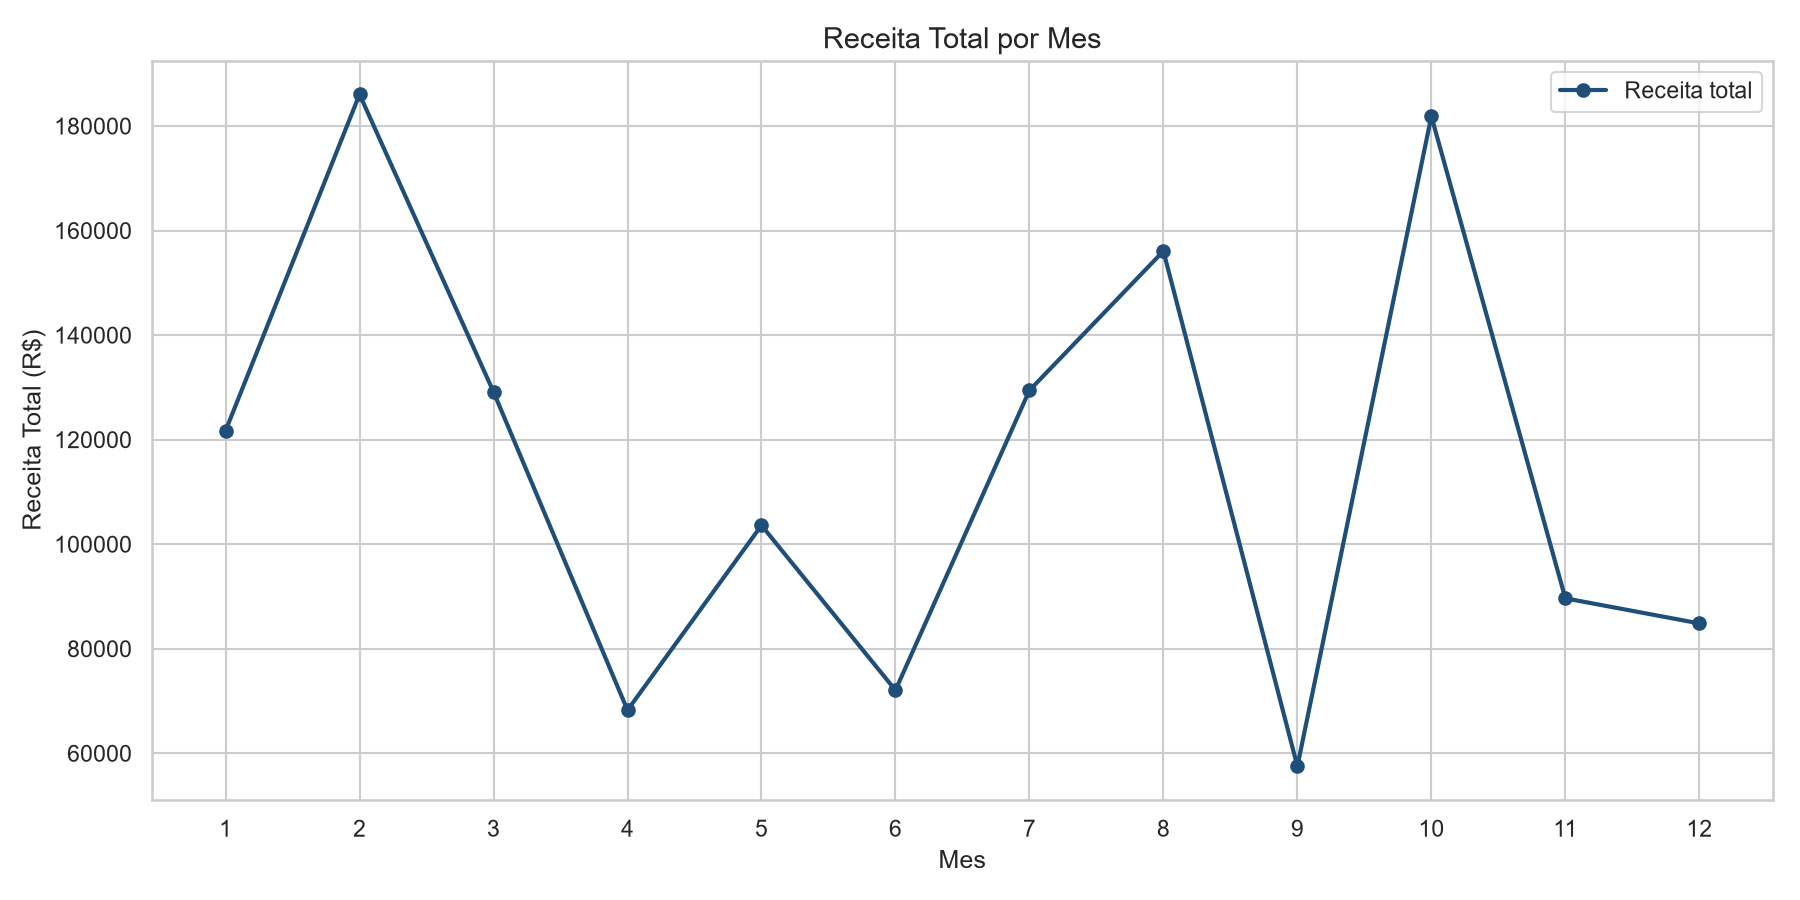

In [10]:
COR_PRINCIPAL = "#1f4e79"  # cor escolhida deliberadamente (nao e o padrao do matplotlib)

def configurar_estilo():
    # tema global do seaborn: fundo com grade leve, mais facil de ler
    sns.set_theme(style="whitegrid")
    # tamanho padrao de qualquer figura criada depois desta linha
    plt.rcParams["figure.figsize"] = (12, 6)
    # tamanho do titulo dos eixos
    plt.rcParams["axes.titlesize"] = 14

def _salvar(fig, nome):
    os.makedirs(PASTA_GRAFICOS, exist_ok=True)  # cria outputs/graficos se nao existir
    fig.tight_layout()  # ajusta margens para nada ficar cortado
    fig.savefig(os.path.join(PASTA_GRAFICOS, nome), dpi=150)  # grava PNG, dpi >= 100 exigido
    plt.close(fig)  # libera a memoria da figura apos salvar

configurar_estilo()  # aplica o tema antes de desenhar

por_mes = metricas["por_mes"]  # pega a tabela "receita por mes" calculada no RF05
fig, ax = plt.subplots(figsize=(12, 6))  # fig = folha inteira; ax = o grafico dentro dela
ax.plot(por_mes["mes"], por_mes["receita_total"], marker="o",  # linha com marcador em cada mes
        linewidth=2, color=COR_PRINCIPAL, label="Receita total")  # cor fixa + rotulo para a legenda
ax.set_title("Receita Total por Mes")  # titulo obrigatorio
ax.set_xlabel("Mes")  # rotulo do eixo X, obrigatorio
ax.set_ylabel("Receita Total (R$)")  # rotulo do eixo Y, obrigatorio
ax.set_xticks(range(1, 13))  # forca os 12 meses aparecerem no eixo X
ax.legend()  # mostra a legenda (o label "Receita total")
_salvar(fig, "receita_por_mes.png")  # grava o arquivo final

from IPython.display import Image, display  # ferramentas do Colab para mostrar a imagem aqui
display(Image(os.path.join(PASTA_GRAFICOS, "receita_por_mes.png")))  # exibe o PNG gravado


## RF07b — Gráfico 2: Top 5 produtos (barras horizontais)

**Por que barras horizontais:** comparar 5 categorias (produtos) sem ordem
temporal — barra é melhor que linha aqui porque não existe "evolução" entre
produtos, só comparação de magnitude. Uso **horizontal** porque os nomes dos
produtos ficam mais legíveis na lateral do que girados no eixo X.

**Comando por comando:**
- `sns.barplot(data=..., y="produto", x="receita_total", hue="produto",
  legend=False, palette="Blues_r", ax=ax)` → gráfico de barras do Seaborn;
  `y`/`x` trocados (em vez do padrão x=categoria, y=valor) é o que torna a
  barra horizontal.
- `hue="produto"` com `legend=False`: preciso de `hue` para usar `palette`,
  mas como cada barra já tem o nome do produto no próprio eixo, a legenda
  seria redundante — por isso desligo com `legend=False`.
- `palette="Blues_r"`: paleta de azuis invertida (`_r`), do mais escuro ao
  mais claro conforme o valor desce.


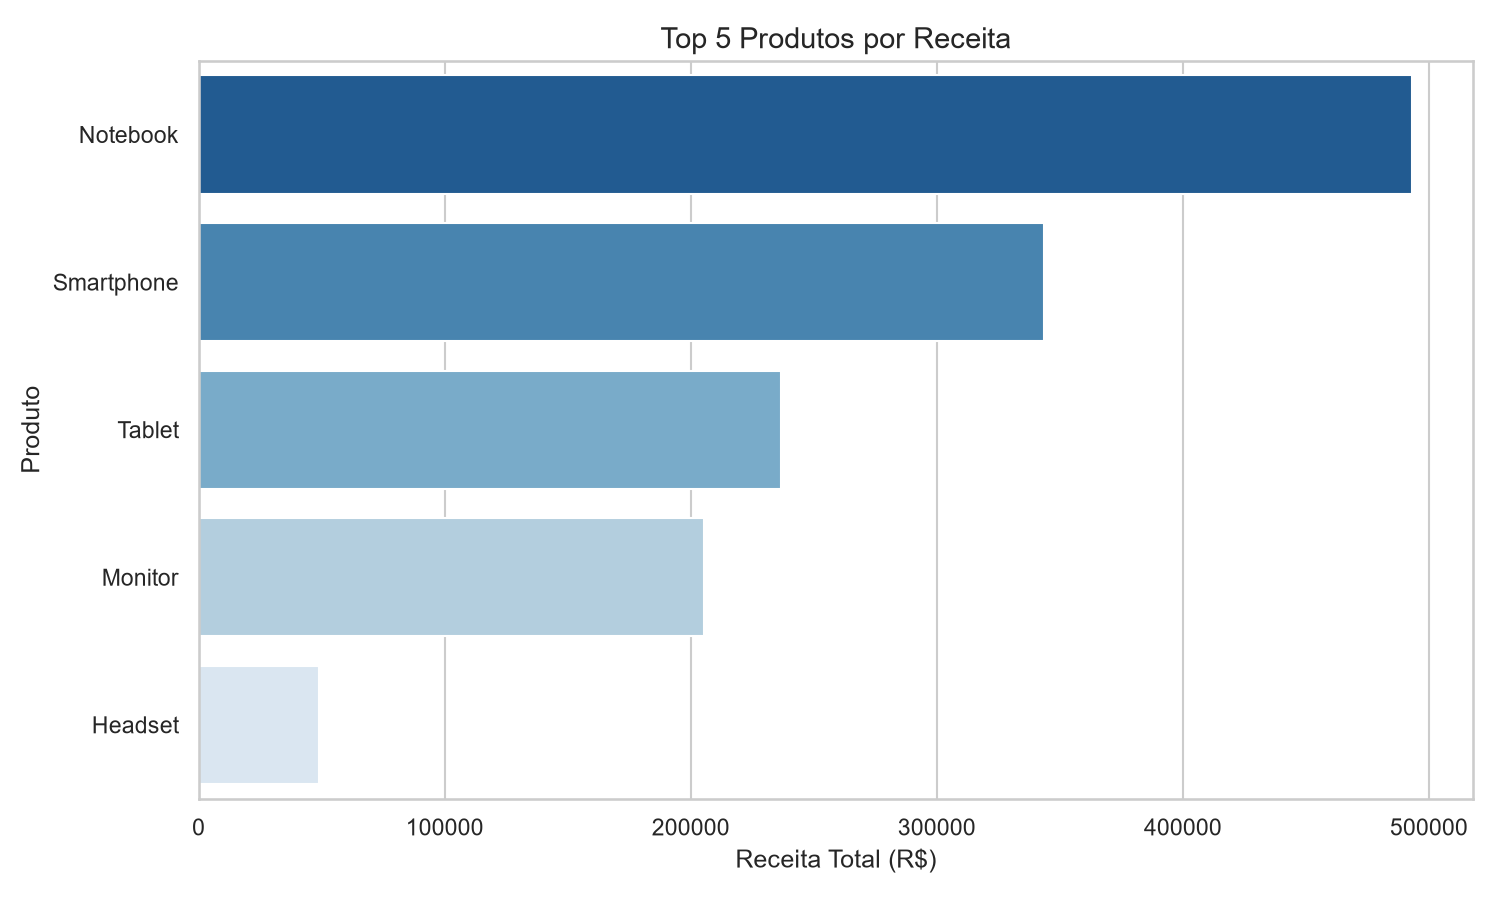

In [11]:
top_produtos = metricas["top_produtos"]  # tabela com os 5 produtos mais vendidos (RF05)
fig, ax = plt.subplots(figsize=(10, 6))  # nova figura, tamanho proprio deste grafico
sns.barplot(data=top_produtos, y="produto", x="receita_total",  # y/x trocados = barra horizontal
            hue="produto", legend=False, palette="Blues_r", ax=ax)  # hue exigido p/ usar palette; legend=False evita redundancia
ax.set_title("Top 5 Produtos por Receita")  # titulo obrigatorio
ax.set_xlabel("Receita Total (R$)")  # rotulo do eixo X
ax.set_ylabel("Produto")  # rotulo do eixo Y
_salvar(fig, "top_produtos.png")  # grava PNG com tight_layout + dpi>=100

display(Image(os.path.join(PASTA_GRAFICOS, "top_produtos.png")))  # mostra o resultado no notebook


## RF07c — Gráfico 3: Quantidade × Receita (dispersão)

**Por que dispersão (scatter):** quero ver a **relação** entre duas variáveis
numéricas por transação (quantidade vendida e receita da venda) — dispersão é
o gráfico certo para mostrar correlação/padrão entre duas variáveis contínuas,
coisa que linha ou barra não mostram bem.

**Comando por comando:**
- `sns.scatterplot(data=df, x="quantidade", y="receita_total",
  hue="categoria", palette=CORES_CATEGORIA, s=70, ax=ax)` → cada ponto é uma
  venda; a cor (`hue="categoria"`) separa visualmente as 3 categorias de
  produto; `s=70` é o tamanho do marcador.
- `CORES_CATEGORIA` é um dicionário fixo (`{"Computadores": "#1f4e79", ...}`)
  para cada categoria sempre usar a mesma cor em todos os gráficos do projeto
  — consistência visual.
- `ax.legend(title="Categoria")` → legenda com título, para identificar qual
  cor é qual categoria.


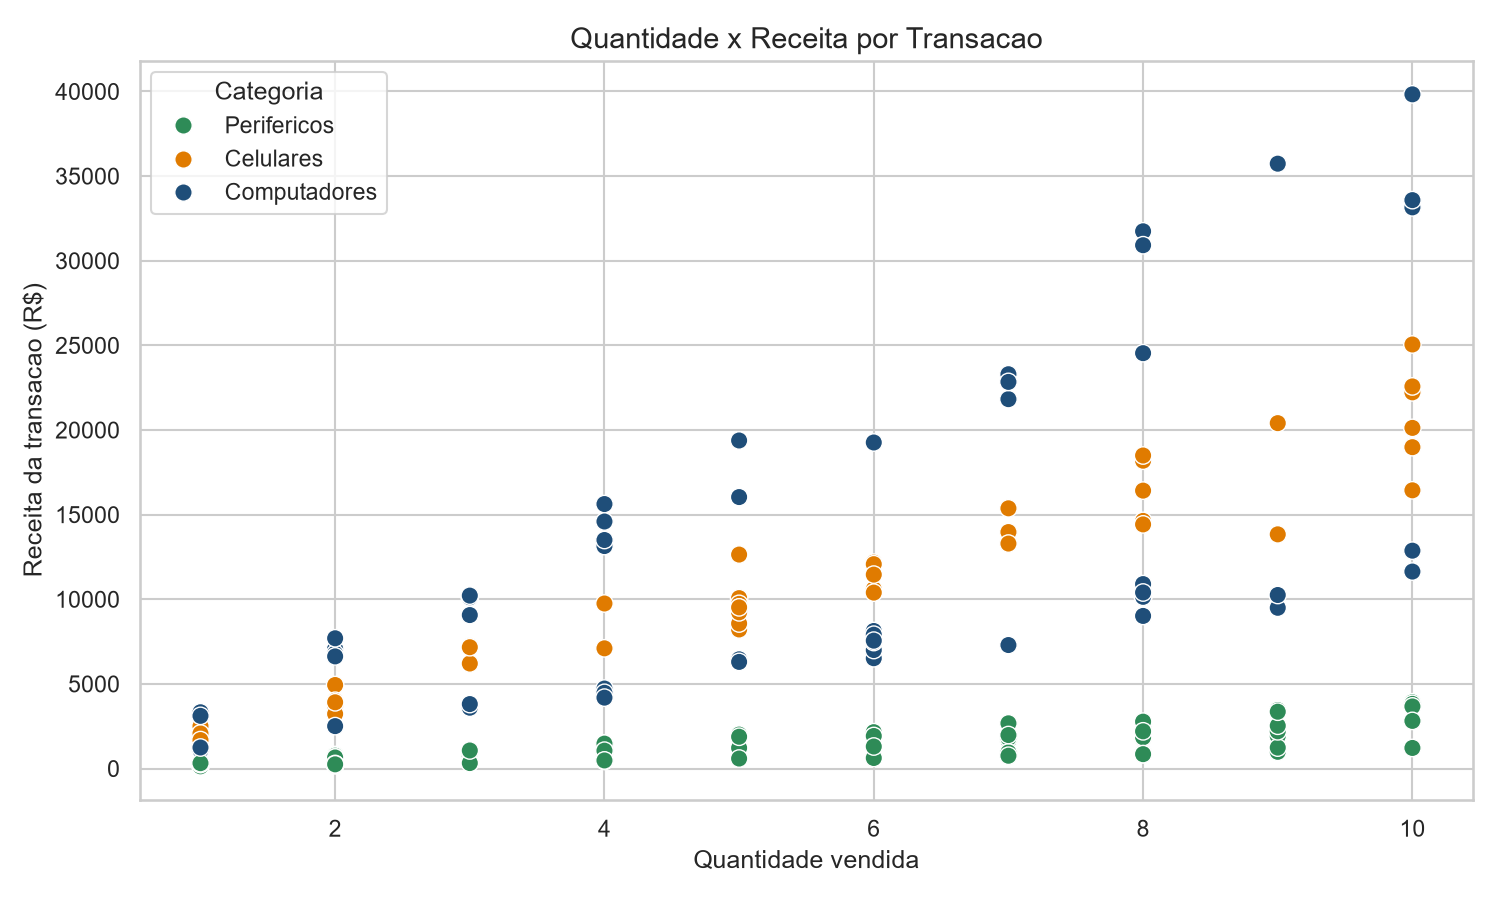

In [12]:
CORES_CATEGORIA = {"Computadores": "#1f4e79", "Celulares": "#e07b00",  # 1 cor fixa por categoria,
                   "Perifericos": "#2e8b57"}  # reaproveitada em todos os graficos do projeto

fig, ax = plt.subplots(figsize=(10, 6))  # nova figura para a dispersao
sns.scatterplot(data=df, x="quantidade", y="receita_total",  # 1 ponto = 1 venda (linha do df limpo)
                hue="categoria", palette=CORES_CATEGORIA, s=70, ax=ax)  # cor por categoria; s=70 = tamanho do ponto
ax.set_title("Quantidade x Receita por Transacao")  # titulo obrigatorio
ax.set_xlabel("Quantidade vendida")  # rotulo do eixo X
ax.set_ylabel("Receita da transacao (R$)")  # rotulo do eixo Y
ax.legend(title="Categoria")  # legenda com titulo, para identificar as cores
_salvar(fig, "quantidade_vs_receita.png")  # grava PNG final

display(Image(os.path.join(PASTA_GRAFICOS, "quantidade_vs_receita.png")))  # mostra o resultado aqui


## RF07d — Gráfico 4: Painel resumo (2×2)

**Por que um painel:** junta as 3 visões anteriores + receita por região em
uma única figura, para uma visão geral de tudo de uma vez — útil como "slide
de resumo" do projeto.

**Comando por comando:**
- `fig, axes = plt.subplots(2, 2, figsize=(14, 9))` → cria uma **matriz** de
  eixos 2 linhas × 2 colunas; `axes` vira indexável como `axes[0, 0]`
  (linha 0, coluna 0 = canto superior esquerdo), `axes[1, 0]` (linha 1,
  coluna 0 = canto inferior esquerdo), etc.
- Cada bloco (`axes[0,0]`, `axes[0,1]`, `axes[1,0]`, `axes[1,1]`) recebe seu
  próprio `.plot()`/`.bar()`/`.scatter()`, título e rótulos — são 4
  "mini-gráficos" independentes dentro da mesma figura.
- `for categoria, grupo in df.groupby("categoria"): axes[1,0].scatter(...)`
  → aqui eu desenho a dispersão manualmente em 3 chamadas (uma por
  categoria), em vez de usar `sns.scatterplot`, porque preciso controlar a
  cor exata de cada grupo dentro de um eixo que já faz parte do painel.
- `fig.suptitle(...)` → um título único para a figura inteira, acima dos 4
  quadrantes.


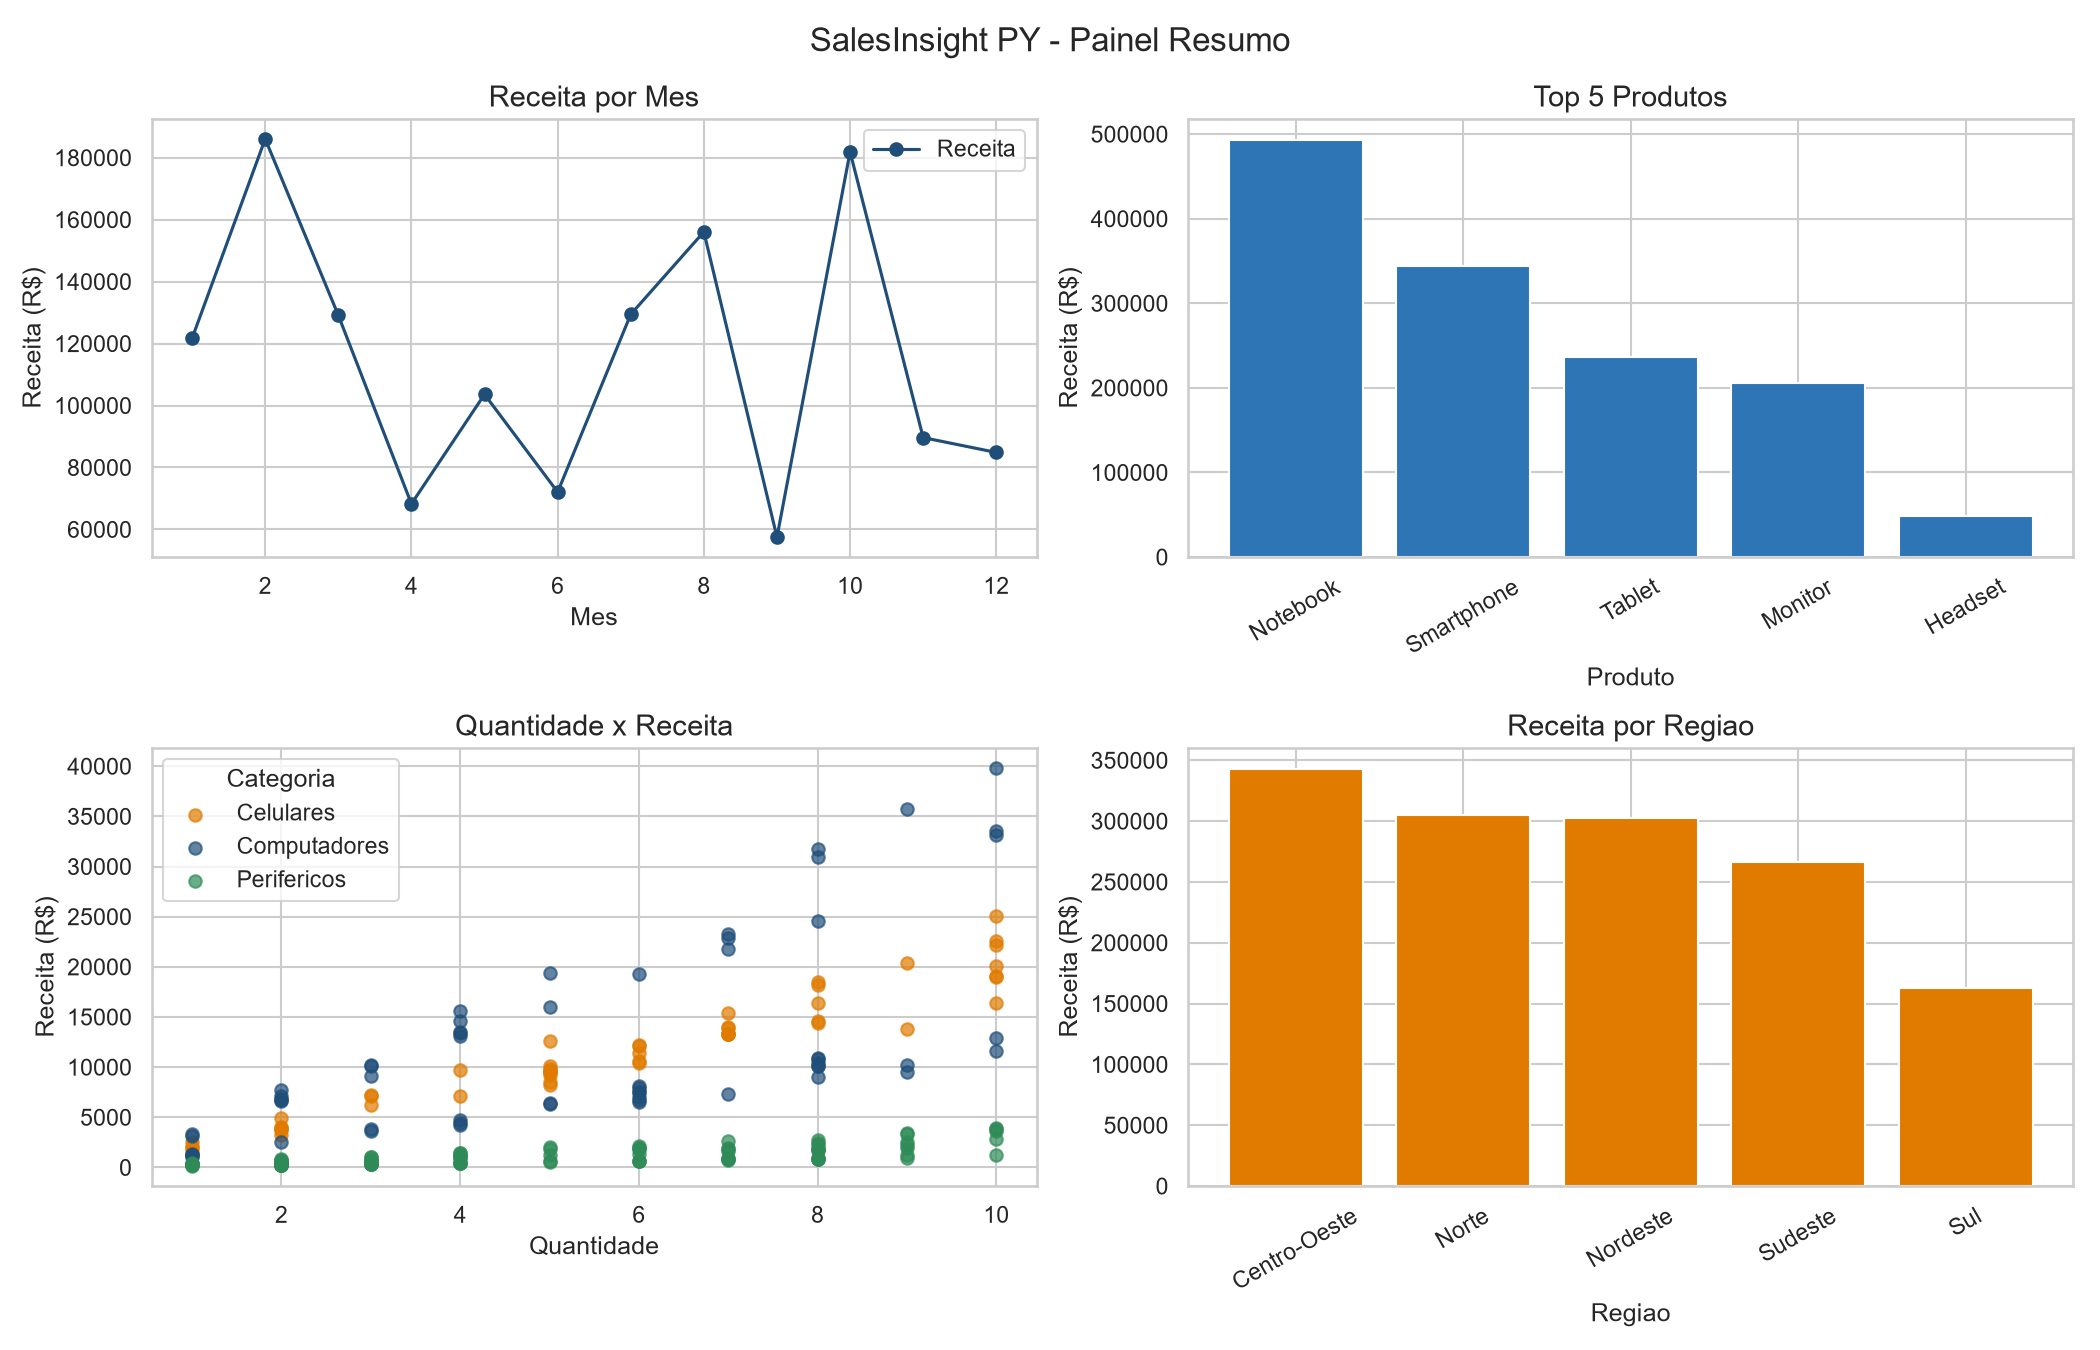

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))  # matriz 2x2 de eixos dentro de 1 figura
por_mes, top = metricas["por_mes"], metricas["top_produtos"]  # reaproveita as tabelas do RF05
regiao = metricas["por_regiao"]  # tabela de receita + ticket medio por regiao

# --- quadrante [0,0]: receita por mes (linha), igual ao Grafico 1 ---
axes[0, 0].plot(por_mes["mes"], por_mes["receita_total"], marker="o",
                color=COR_PRINCIPAL, label="Receita")
axes[0, 0].set_title("Receita por Mes")  # titulo deste quadrante
axes[0, 0].set_xlabel("Mes")
axes[0, 0].set_ylabel("Receita (R$)")
axes[0, 0].legend()

# --- quadrante [0,1]: top 5 produtos (barra vertical, versao simplificada do Grafico 2) ---
axes[0, 1].bar(top["produto"], top["receita_total"], color="#2e75b6")
axes[0, 1].set_title("Top 5 Produtos")
axes[0, 1].set_xlabel("Produto")
axes[0, 1].set_ylabel("Receita (R$)")
axes[0, 1].tick_params(axis="x", rotation=30)  # gira os nomes dos produtos para nao sobrepor

# --- quadrante [1,0]: dispersao quantidade x receita, 1 scatter por categoria (3 chamadas) ---
for categoria, grupo in df.groupby("categoria"):  # separa o df em 3 grupos por categoria
    axes[1, 0].scatter(grupo["quantidade"], grupo["receita_total"],
                       color=CORES_CATEGORIA[categoria], label=categoria,  # mesma cor do Grafico 3
                       alpha=0.7)  # alpha = transparencia, ajuda a ver pontos sobrepostos
axes[1, 0].set_title("Quantidade x Receita")
axes[1, 0].set_xlabel("Quantidade")
axes[1, 0].set_ylabel("Receita (R$)")
axes[1, 0].legend(title="Categoria")

# --- quadrante [1,1]: receita por regiao (unico grafico do projeto so neste painel) ---
axes[1, 1].bar(regiao["regiao"], regiao["receita_total"], color="#e07b00")
axes[1, 1].set_title("Receita por Regiao")
axes[1, 1].set_xlabel("Regiao")
axes[1, 1].set_ylabel("Receita (R$)")
axes[1, 1].tick_params(axis="x", rotation=30)

fig.suptitle("SalesInsight PY - Painel Resumo", fontsize=16)  # titulo geral, acima dos 4 quadrantes
_salvar(fig, "painel_resumo.png")  # grava o PNG final do painel

display(Image(os.path.join(PASTA_GRAFICOS, "painel_resumo.png")))  # mostra o resultado aqui


## Bônus — Regressão linear: receita em função da quantidade

**Não é exigido** (regressão é conteúdo da Semana 13). Entra como gráfico
adicional (bônus B04), para responder a pergunta do desafio: "existe relação
entre a quantidade vendida e a receita gerada por transação?"

**As duas variáveis:**
- **X, independente:** `quantidade`, o que o cliente decide comprar.
- **Y, dependente:** `receita_total`, o valor que resulta da venda.

**Comando por comando:**
- `np.polyfit(x, y, 1)` → encontra a reta `y = inclinacao * x + intercepto`
  que passa o mais perto possível de todos os pontos (mínimos quadrados). O
  `1` é o grau do polinômio: grau 1 = reta.
- `np.corrcoef(x, y)[0, 1] ** 2` → o R², de 0 a 1: quanto da variação da
  receita a reta consegue explicar.
- `np.linspace(1, 10, 50)` → 50 pontos de 1 a 10 para desenhar a reta.

**Como ler o resultado:** a inclinação é o quanto a receita sobe a cada
unidade a mais, ou seja, o **preço médio por unidade** da categoria.
Celulares fica perto de R$ 2.000 com R² alto (0,93): Smartphone e Tablet
têm preços parecidos. Computadores tem R² baixo (0,43) porque mistura
Notebook (R$ 3.500) e Monitor (R$ 1.200) na mesma reta.


   categoria  inclinacao  intercepto    r2
   Celulares     2023.80     -130.60 0.930
Computadores     2200.91      278.85 0.428
 Perifericos      253.84     -104.79 0.585


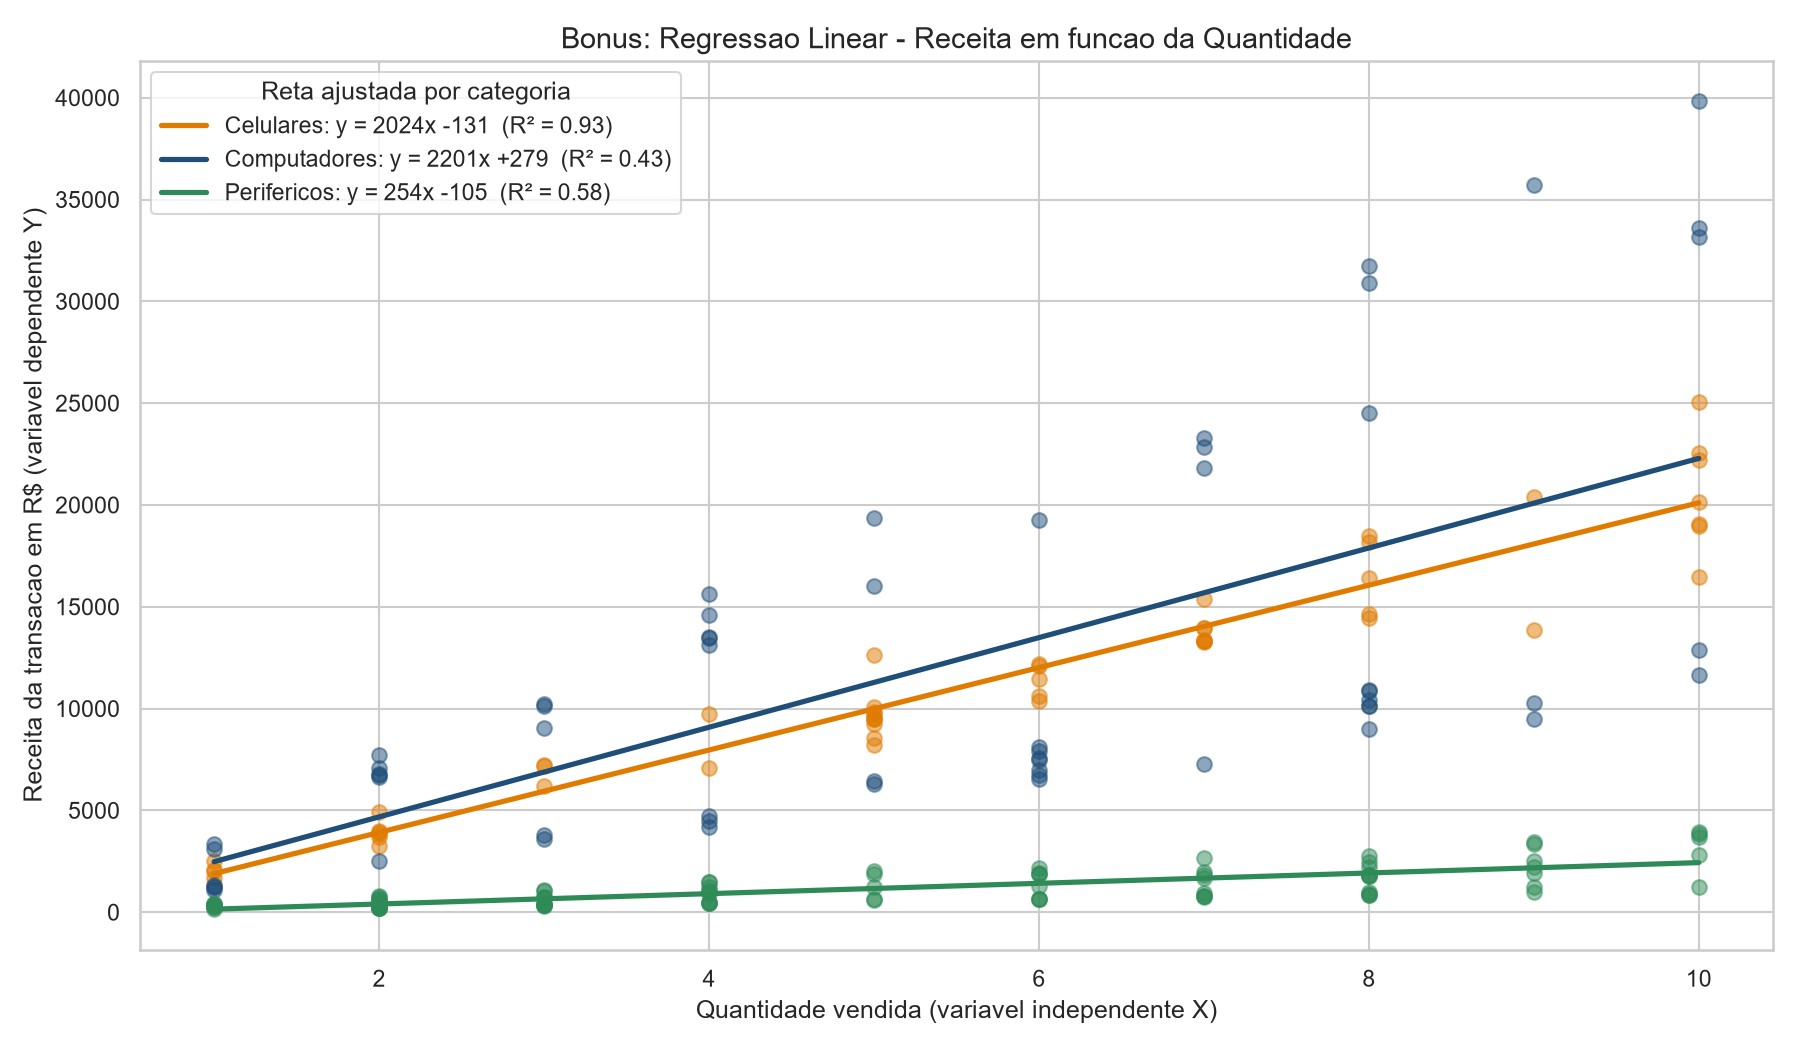

In [14]:
def grafico_regressao_bonus(df):
    fig, ax = plt.subplots(figsize=(12, 7))  # figura do bonus
    xs = np.linspace(1, 10, 50)  # pontos de 1 a 10 para desenhar a reta
    linhas = []
    for categoria, grupo in df.groupby("categoria"):  # uma reta por categoria
        x, y = grupo["quantidade"], grupo["receita_total"]  # X independente, Y dependente
        inclinacao, intercepto = np.polyfit(x, y, 1)  # reta de minimos quadrados
        r2 = np.corrcoef(x, y)[0, 1] ** 2  # R2: quanto a reta explica (0 a 1)
        cor = CORES_CATEGORIA[categoria]  # mesma cor da categoria nos outros graficos
        ax.scatter(x, y, color=cor, alpha=0.5, s=50)  # pontos reais
        ax.plot(xs, inclinacao * xs + intercepto, color=cor, linewidth=2.5,  # a reta ajustada
                label=f"{categoria}: y = {inclinacao:.0f}x {intercepto:+.0f}  (R² = {r2:.2f})")
        linhas.append({"categoria": categoria, "inclinacao": round(inclinacao, 2),
                       "intercepto": round(intercepto, 2), "r2": round(r2, 3)})
    ax.set_title("Bonus: Regressao Linear - Receita em funcao da Quantidade")
    ax.set_xlabel("Quantidade vendida (variavel independente X)")
    ax.set_ylabel("Receita da transacao em R$ (variavel dependente Y)")
    ax.legend(title="Reta ajustada por categoria")  # equacao e R2 na legenda
    _salvar(fig, "bonus_regressao.png")
    return pd.DataFrame(linhas)

coeficientes = grafico_regressao_bonus(df)
print(coeficientes.to_string(index=False))
display(Image(os.path.join(PASTA_GRAFICOS, "bonus_regressao.png")))


## RF09 — Exportar resultados (CSV e JSON)

**O que é:** grava os resultados em disco para quem for avaliar o trabalho
não precisar rodar o código para ver as métricas.

**Comando por comando:**
- `.to_csv(caminho, index=False, encoding="utf-8-sig")` → grava CSV sem
  coluna de índice numérico extra; `utf-8-sig` garante que o Excel abra os
  acentos corretamente.
- `{k: round(float(v), 2) for k, v in estatisticas.items()}` → converte cada
  valor para `float` nativo do Python **antes** de gravar em JSON, porque o
  JSON não aceita tipos do NumPy (`numpy.float64`) mesmo que pareçam número
  comum.
- `json.dump(obj, f, indent=4, ensure_ascii=False)` → grava formatado, com
  acentos preservados (`ensure_ascii=False`).
- `json.load(f)` logo depois → relê o arquivo gravado, como prova de que a
  gravação funcionou e o JSON é válido.


In [15]:
def exportar_resultados(metricas, clientes, estatisticas):
    """Grava CSVs e JSON e le o JSON de volta para conferencia."""
    os.makedirs(PASTA_SAIDA, exist_ok=True)
    metricas["por_mes"].to_csv(
        os.path.join(PASTA_SAIDA, "metricas_por_mes.csv"),
        index=False, encoding="utf-8-sig")
    clientes.to_csv(
        os.path.join(PASTA_SAIDA, "segmentacao_clientes.csv"),
        index=False, encoding="utf-8-sig")

    serializavel = {k: round(float(v), 2) for k, v in estatisticas.items()}
    caminho = os.path.join(PASTA_SAIDA, "estatisticas_gerais.json")
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(serializavel, f, indent=4, ensure_ascii=False)

    with open(caminho, "r", encoding="utf-8") as f:
        conferencia = json.load(f)
    print(f"\nJSON gravado e lido de volta: {conferencia}")
    return conferencia

estatisticas = {
    "receita_total": df["receita_total"].sum(),
    "ticket_medio": df["receita_total"].mean(),
    "n_vendas": len(df),
    "n_clientes": df["cliente"].nunique(),
    "linhas_removidas": relatorio_limpeza["datas_invalidas_removidas"],
}
exportar_resultados(metricas, clientes, estatisticas)



JSON gravado e lido de volta: {'receita_total': 1380210.31, 'ticket_medio': 7114.49, 'n_vendas': 194.0, 'n_clientes': 49.0, 'linhas_removidas': 6.0}


{'receita_total': 1380210.31,
 'ticket_medio': 7114.49,
 'n_vendas': 194.0,
 'n_clientes': 49.0,
 'linhas_removidas': 6.0}

## RF10 — Orquestração (classe `AnalisadorDeVendas`)

**O que é:** a versão final do projeto (`salesinsight.py`) organiza tudo isso
que rodamos célula a célula dentro de uma **classe**, que guarda o estado
(`self.df`, `self.metricas`, `self.clientes`) entre as etapas, e uma função
`main()` que executa a ordem certa: carregar → inspecionar → transformar →
analisar → visualizar → resumo.

**Por que isso importa para a apresentação:** no vídeo, depois de explicar
cada célula manualmente (como fizemos aqui), mostre que o mesmo fluxo existe
de forma organizada no arquivo `salesinsight.py`, executável com um único
comando:

```bash
python salesinsight.py
```

Isso demonstra que você entende tanto o passo a passo (este notebook) quanto
a versão organizada em produção (o script completo).


In [16]:
print("Fluxo completo executado neste notebook, celula por celula.")
print("A versao organizada em classe esta em salesinsight.py, executavel com:")
print("    python salesinsight.py")


Fluxo completo executado neste notebook, celula por celula.
A versao organizada em classe esta em salesinsight.py, executavel com:
    python salesinsight.py
